## Midline traces (development)

Plots midline/tail traces from pose data for young, medium, and old fish. 

Calculate the position of the stable node in the trunk relative to the tip of the head.

Figures are saved to the project `figures/` directory and to `midline_dynamics/media/`.

Import libraries:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
import sys
from pathlib import Path
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import INPUT_DATA_DIR, FIGURES_DIR, notebook_media_dir
%load_ext autoreload
%autoreload 2
    
from functions.visual_flow_behavior_plotting import *
from functions.visual_flow_behavior_analysis import *
from functions.brain_analysis import *
from functions.utilities import *
from functions.freely_swimming import *

import os
import h5py
from ipywidgets import interact,IntSlider
from scipy import fft
from scipy.ndimage import gaussian_filter
from skimage import io
import pickle
from scipy import fft
from sklearn.preprocessing import scale
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from scipy.stats import iqr
import pandas as pd

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [26]:
from functions.MC_utilities import *
color_y = ('cyan')
color_m = ('green')
color_o = ('yellow')


In [3]:
# Paths from code/paths.py (input_data, figures, local media)
path = str(INPUT_DATA_DIR)
path_figures = str(FIGURES_DIR)
path_media = str(notebook_media_dir("midline_dynamics"))
path

'<repo>/input_data'

In [4]:
date=date.today().strftime('%Y-%m-%d')
date

'2026-01-28'

#### Import data:

In [5]:
speed = load_h5(path, 'SPEED')[0]

📥 Loaded SPEED ← <repo>/input_data/SPEED.h5


In [6]:
theta = pd.read_hdf(os.path.join(path, f"THETA_obs.h5"), key='df')

In [7]:
pose = pd.read_hdf(os.path.join(path, f"POSE.h5"), key='df')

In [8]:
fish_ids=theta['ID'].unique()
fish_ids

array(['13_06May24_1', '13_30Oct24_3', '13_30Oct24_4', '14_31Oct24_1',
       '15_13Jun24_1', '15_13Jun24_2', '15_13Jun24_3', '17_21May24_2',
       '18_22May24_1', '18_22May24_2', '19_23May24_5', '20_05Jun24_1',
       '20_05Jun24_2', '20_12Jun24_1', '21_06Jun24_1', '25_10Jun24_1',
       '26_02May24_2', '27_12Jun24_1', '28_04May24_1', '30_06May24_2'],
      dtype=object)

In [9]:
len(fish_ids)

20

In [10]:
fish_ids_young=['13_06May24_1','13_30Oct24_3','13_30Oct24_4','14_27Mar24_1','14_31Oct24_1']

In [11]:
fish_ids_intermediate=['17_21May24_2','18_22May24_1','18_22May24_2','19_23May24_5','20_05Jun24_1','20_05Jun24_2','20_12Jun24_1','21_06Dec24_1','21_06Dec24_2','21_06Jun24_1','25_10Jun24_1']

In [12]:
fish_ids_old=['26_02May24_2','27_12Jun24_1','28_04May24_1','30_06May24_2','34_11Dec24_1','34_11Dec24_3']

In [13]:
fish_ids=fish_ids_young+fish_ids_intermediate+fish_ids_old

In [14]:
len(fish_ids)

22

In [15]:
fish_ids

['13_06May24_1',
 '13_30Oct24_3',
 '13_30Oct24_4',
 '14_27Mar24_1',
 '14_31Oct24_1',
 '17_21May24_2',
 '18_22May24_1',
 '18_22May24_2',
 '19_23May24_5',
 '20_05Jun24_1',
 '20_05Jun24_2',
 '20_12Jun24_1',
 '21_06Dec24_1',
 '21_06Dec24_2',
 '21_06Jun24_1',
 '25_10Jun24_1',
 '26_02May24_2',
 '27_12Jun24_1',
 '28_04May24_1',
 '30_06May24_2',
 '34_11Dec24_1',
 '34_11Dec24_3']

# Midline trace, young

In [16]:
speed_clean = pd.DataFrame()

fish_ID = '13_06May24_1'
speed_fish,theta_fish,pose_fish=subset_by_fish(fish_ID,DF1=speed,DF2=theta,DF3=pose)
L=theta_fish['L_av'].values[0]
thetas_fish = pose_fish.filter(like='theta').values

ttail=theta_fish['t'].values
angletail=theta_fish['theta'].values

tfish=speed_fish['t'].values
vfish=speed_fish['speed_gauss'].values

tail_points_yaxis=compute_tail_points_from_pose_angles(thetas_fish,L)
tail_points_yaxis = tail_points_yaxis[:, :-1, :] #exclude last point, too noisy

Subsetting data of the fish 13_06May24_1


100%|██████████| 143367/143367 [00:07<00:00, 19914.29it/s]


In [17]:
tail_points = np.empty_like(tail_points_yaxis)
tail_points[..., 0] = -tail_points_yaxis[..., 1]
tail_points[..., 1] =  tail_points_yaxis[..., 0]

tail_points.shape

(143367, 19, 2)

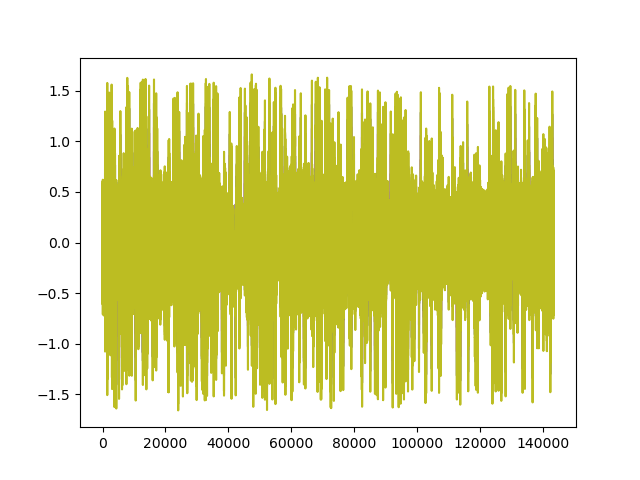

In [18]:
%matplotlib widget
plt.figure()
plt.plot(tail_points[:, :, 1])
plt.show()

In [20]:
dframe = 250
frame_start = 32111
frame_end = frame_start + dframe

tail_points_interp_y = np.zeros_like(tail_points[frame_start:frame_end, :, :])
x_tail_new = np.nanmean(tail_points[:, :, 0], axis=0)

for i, frame in enumerate(range(frame_start, frame_end)):
    f = interp1d(tail_points[frame, :, 0], 
                 tail_points[frame, :, 1], 
                 kind='linear', 
                 bounds_error=False, 
                 fill_value='extrapolate')
    y_interp = f(x_tail_new)
    tail_points_interp_y[i] = np.column_stack([x_tail_new, y_interp])
    

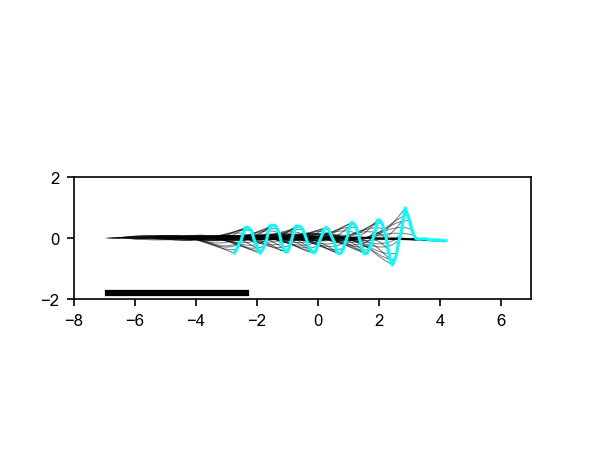

In [28]:
dx = 0.07
red_x = []
red_y = []

default()
widget()
arial()

fig = plt.figure(figsize=(10 / 2.54, 8 / 2.54),dpi=150)

for i, frame in enumerate(range(100)):
    x_shifted = tail_points_interp_y[frame, :, 0] - i * dx#+ i * dx
    y = -tail_points_interp_y[frame, :, 1]

    plt.plot(x_shifted, y, 'k-', alpha=0.5, linewidth=0.5)

    # Tail tip (last point)
    tail_tip_x = x_shifted[-1]
    tail_tip_y = y[-1]
    red_x.append(tail_tip_x)
    red_y.append(tail_tip_y)

# Connect red dots with a line
plt.plot(red_x, red_y, '-', color=color_y, linewidth=1.5)

# --- Add scale bar ---
ax = plt.gca()
ax.set_aspect('equal')

# Choose position for scalebar
x0 = ax.get_xlim()[0] + 0.05 * (ax.get_xlim()[1] - ax.get_xlim()[0])  # 5% from left
y0 = ax.get_ylim()[0] - 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0])  # slightly below

y0=-1.8
ax.plot([x0, x0 + L], [y0, y0], 'k-', linewidth=3)

ax.set_ylim(-2,2)
ax.set_xlim(-8,7)

fig.savefig(os.path.join(path_figures, "Fig_1e_midline_young.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_1e_midline_young.pdf"), format="pdf", bbox_inches='tight', dpi=200)

plt.show()

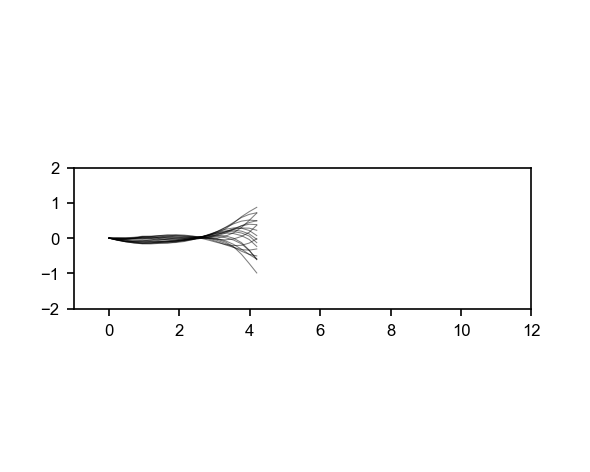

In [29]:
dx = 0.07
red_x = []
red_y = []

default()
widget()
arial()

fig = plt.figure(figsize=(10 / 2.54, 8 / 2.54),dpi=150)

for i, frame in enumerate(range(19)):
    frame0 = 19+ frame
    x_shifted = tail_points_interp_y[frame0, :, 0] 
    y = tail_points_interp_y[frame0, :, 1]

    plt.plot(x_shifted, y, 'k-', alpha=0.5, linewidth=0.5)

    # Tail tip (last point)
    tail_tip_x = x_shifted[-1]
    tail_tip_y = y[-1]
    red_x.append(tail_tip_x)
    red_y.append(tail_tip_y)

# Connect red dots with a line
#plt.plot(red_x, red_y, '-', color=color_y, linewidth=1)

# --- Add scale bar ---
ax = plt.gca()
ax.set_aspect('equal')

# Choose position for scalebar
x0 = ax.get_xlim()[0] + 0.05 * (ax.get_xlim()[1] - ax.get_xlim()[0])  # 5% from left
y0 = ax.get_ylim()[0] - 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0])  # slightly below


ax.set_ylim(-2,2)
ax.set_xlim(-1,12)
#fig.savefig(os.path.join(path_figures, "midline_young_overimposed.pdf"), format="pdf")

plt.show()

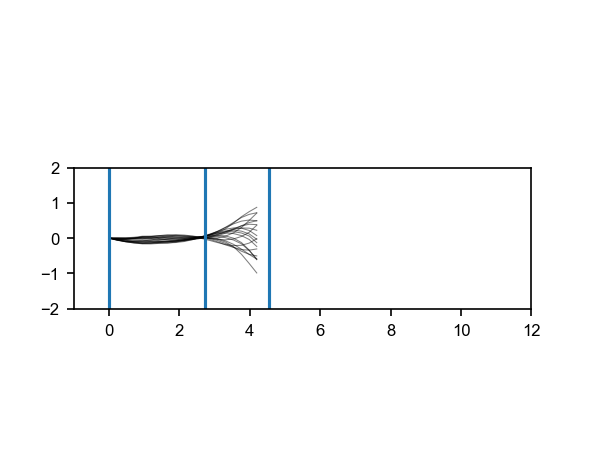

In [30]:
dx = 0.07
red_x = []
red_y = []

default()
widget()
arial()

fig = plt.figure(figsize=(10 / 2.54, 8 / 2.54),dpi=150)

for i, frame in enumerate(range(19)):
    frame0 = 19+ frame
    x_shifted = tail_points_interp_y[frame0, :, 0] 
    y = tail_points_interp_y[frame0, :, 1]

    plt.plot(x_shifted, y, 'k-', alpha=0.5, linewidth=0.5)

    # Tail tip (last point)
    tail_tip_x = x_shifted[-1]
    tail_tip_y = y[-1]
    red_x.append(tail_tip_x)
    red_y.append(tail_tip_y)

# Connect red dots with a line
#plt.plot(red_x, red_y, '-', color=color_y, linewidth=1)

# --- Add scale bar ---
ax = plt.gca()
ax.set_aspect('equal')

# Choose position for scalebar
x0 = ax.get_xlim()[0] + 0.05 * (ax.get_xlim()[1] - ax.get_xlim()[0])  # 5% from left
y0 = ax.get_ylim()[0] - 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0])  # slightly below


ax.set_ylim(-2,2)
ax.set_xlim(-1,12)

ax.axvline(x = 0)
ax.axvline(x = L)
ax.axvline(x = L*3/5)

#fig.savefig(os.path.join(path_figures, "midline_young_overimposed.pdf"), format="pdf")

plt.show()

In [31]:
L

4.530332158523153

# Midline trace, medium

In [32]:
speed_clean = pd.DataFrame()

fish_ID = '20_05Jun24_2'
speed_fish,theta_fish,pose_fish=subset_by_fish(fish_ID,DF1=speed,DF2=theta,DF3=pose)
L=theta_fish['L_av'].values[0]
thetas_fish = pose_fish.filter(like='theta').values

ttail=theta_fish['t'].values
angletail=theta_fish['theta'].values

tfish=speed_fish['t'].values
vfish=speed_fish['speed_gauss'].values

tail_points_yaxis=compute_tail_points_from_pose_angles(thetas_fish,L)
tail_points_yaxis = tail_points_yaxis[:, :-1, :] #exclude last point, too noisy

Subsetting data of the fish 20_05Jun24_2


100%|██████████| 673569/673569 [00:32<00:00, 20757.95it/s]


In [33]:
tail_points = np.empty_like(tail_points_yaxis)
tail_points[..., 0] = -tail_points_yaxis[..., 1]
tail_points[..., 1] =  tail_points_yaxis[..., 0]

tail_points.shape

(673569, 19, 2)

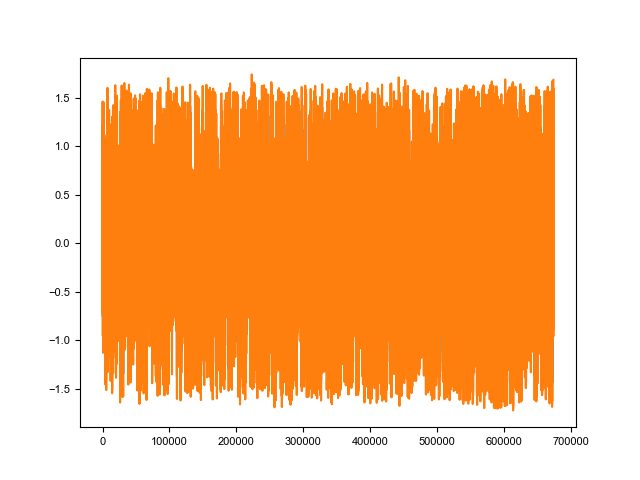

In [34]:
%matplotlib widget
plt.figure()
plt.plot(tail_points[:, -2:, 1])
plt.show()

In [35]:
dframe = 250
frame_start = 183360
frame_end = frame_start + dframe

tail_points_interp_m = np.zeros_like(tail_points[frame_start:frame_end, :, :])
x_tail_new = np.nanmean(tail_points[:, :, 0], axis=0)

for i, frame in enumerate(range(frame_start, frame_end)):
    f = interp1d(tail_points[frame, :, 0], 
                 tail_points[frame, :, 1], 
                 kind='linear', 
                 bounds_error=False, 
                 fill_value='extrapolate')
    y_interp = f(x_tail_new)
    tail_points_interp_m[i] = np.column_stack([x_tail_new, y_interp])
    

In [36]:
tail_points_interp_m = tail_points_interp_m[:, :-1, :]


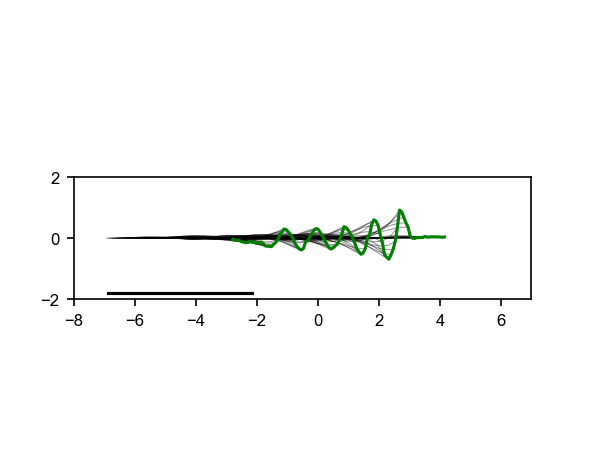

In [38]:
dx = 0.07
red_x = []
red_y = []

default()
widget()
arial()

fig = plt.figure(figsize=(10 / 2.54, 8 / 2.54),dpi=150)

for i, frame in enumerate(range(100)):
    x_shifted = tail_points_interp_m[frame, :, 0] - i * dx #+ i * dx
    y = tail_points_interp_m[frame, :, 1]

    plt.plot(x_shifted, y, 'k-', alpha=0.4, linewidth=0.5)

    # Tail tip (last point)
    tail_tip_x = x_shifted[-1]
    tail_tip_y = y[-1]
    red_x.append(tail_tip_x)
    red_y.append(tail_tip_y)

# Connect red dots with a line
plt.plot(red_x, red_y, '-', color=color_m, linewidth=1.5)

# --- Add scale bar ---
ax = plt.gca()
ax.set_aspect('equal')

# Choose position for scalebar
x0 = ax.get_xlim()[0] + 0.05 * (ax.get_xlim()[1] - ax.get_xlim()[0])  # 5% from left
y0 = ax.get_ylim()[0] - 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0])  # slightly below

y0=-1.8
ax.plot([x0, x0 + L], [y0, y0], 'k-', linewidth=1.5)

ax.set_ylim(-2,2)
ax.set_xlim(-8,7)

fig.savefig(os.path.join(path_figures, "Fig_1e_midline_medium.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_1e_midline_medium.pdf"), format="pdf", bbox_inches='tight', dpi=200)

plt.show()

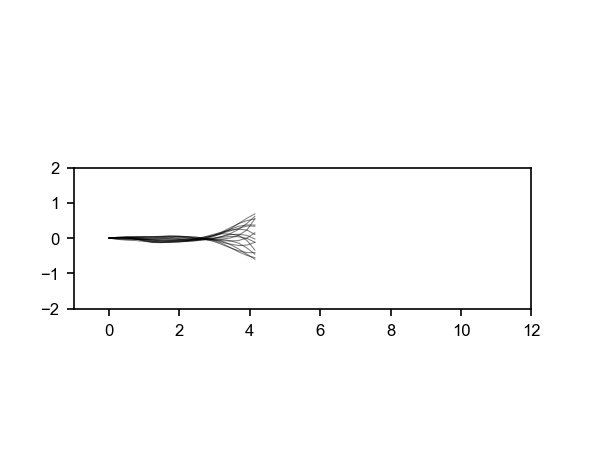

In [39]:
dx = 0.07
red_x = []
red_y = []

default()
widget()
arial()

fig = plt.figure(figsize=(10 / 2.54, 8 / 2.54),dpi=150)

for i, frame in enumerate(range(16)):
    frame0 = 22 + frame
    x_shifted = tail_points_interp_m[frame0, :, 0] 
    y = -tail_points_interp_m[frame0, :, 1]

    plt.plot(x_shifted, y, 'k-', alpha=0.5, linewidth=0.5)

    # Tail tip (last point)
    tail_tip_x = x_shifted[-1]
    tail_tip_y = y[-1]
    red_x.append(tail_tip_x)
    red_y.append(tail_tip_y)

# Connect red dots with a line
#plt.plot(red_x, red_y, '-', color=color_y, linewidth=1)

# --- Add scale bar ---
ax = plt.gca()
ax.set_aspect('equal')

# Choose position for scalebar
x0 = ax.get_xlim()[0] + 0.05 * (ax.get_xlim()[1] - ax.get_xlim()[0])  # 5% from left
y0 = ax.get_ylim()[0] - 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0])  # slightly below


ax.set_ylim(-2,2)
ax.set_xlim(-1,12)
#fig.savefig(os.path.join(path_figures, "midline_medium_overimposed.pdf"), format="pdf")

plt.show()

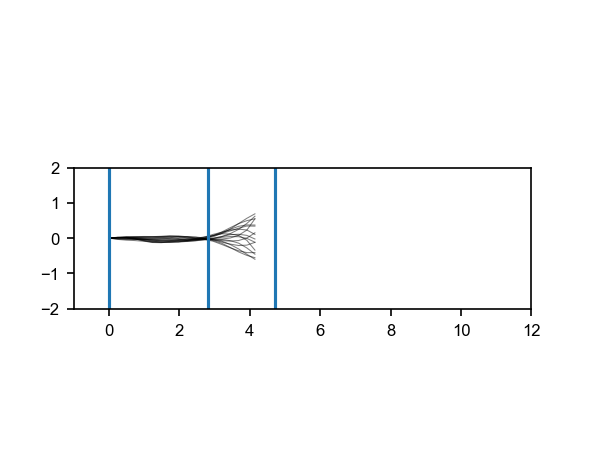

In [40]:
dx = 0.07
red_x = []
red_y = []

default()
widget()
arial()

fig = plt.figure(figsize=(10 / 2.54, 8 / 2.54),dpi=150)

for i, frame in enumerate(range(16)):
    frame0 = 22 + frame
    x_shifted = tail_points_interp_m[frame0, :, 0] 
    y = -tail_points_interp_m[frame0, :, 1]

    plt.plot(x_shifted, y, 'k-', alpha=0.5, linewidth=0.5)

    # Tail tip (last point)
    tail_tip_x = x_shifted[-1]
    tail_tip_y = y[-1]
    red_x.append(tail_tip_x)
    red_y.append(tail_tip_y)

# Connect red dots with a line
#plt.plot(red_x, red_y, '-', color=color_y, linewidth=1)

# --- Add scale bar ---
ax = plt.gca()
ax.set_aspect('equal')

# Choose position for scalebar
x0 = ax.get_xlim()[0] + 0.05 * (ax.get_xlim()[1] - ax.get_xlim()[0])  # 5% from left
y0 = ax.get_ylim()[0] - 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0])  # slightly below


ax.set_ylim(-2,2)
ax.set_xlim(-1,12)
#fig.savefig(os.path.join(path_figures, "midline_medium_overimposed.pdf"), format="pdf")


ax.axvline(x = 0)
ax.axvline(x = L)
ax.axvline(x = L*3/5)


plt.show()

# Midline trace, old

In [41]:
speed_clean = pd.DataFrame()

fish_ID = '30_06May24_2'
speed_fish,theta_fish,pose_fish=subset_by_fish(fish_ID,DF1=speed,DF2=theta,DF3=pose)
L=theta_fish['L_av'].values[0]
thetas_fish = pose_fish.filter(like='theta').values

ttail=theta_fish['t'].values
angletail=theta_fish['theta'].values

tfish=speed_fish['t'].values
vfish=speed_fish['speed_gauss'].values

tail_points_yaxis=compute_tail_points_from_pose_angles(thetas_fish,L)
tail_points_yaxis = tail_points_yaxis[:, :-1, :] #exclude last point, too noisy

Subsetting data of the fish 30_06May24_2


100%|██████████| 276078/276078 [00:13<00:00, 20185.86it/s]


In [42]:
tail_points = np.empty_like(tail_points_yaxis)
tail_points[..., 0] = -tail_points_yaxis[..., 1]
tail_points[..., 1] =  tail_points_yaxis[..., 0]

tail_points.shape

(276078, 19, 2)

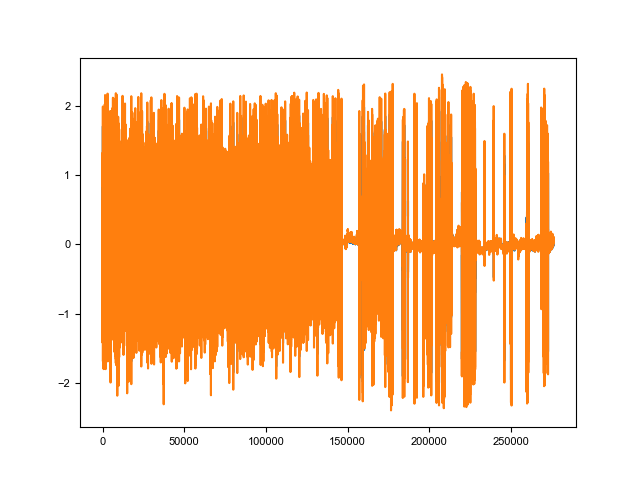

In [43]:
%matplotlib widget
plt.figure()
plt.plot(tail_points[:, -2:, 1])
plt.show()

In [44]:
dframe = 250
frame_start = 80750
frame_end = frame_start + dframe

tail_points_interp_o = np.zeros_like(tail_points[frame_start:frame_end, :, :])
x_tail_new = np.nanmean(tail_points[:, :, 0], axis=0)

for i, frame in enumerate(range(frame_start, frame_end)):
    f = interp1d(tail_points[frame, :, 0], 
                 tail_points[frame, :, 1], 
                 kind='linear', 
                 bounds_error=False, 
                 fill_value='extrapolate')
    y_interp = f(x_tail_new)
    tail_points_interp_o[i] = np.column_stack([x_tail_new, y_interp])
    

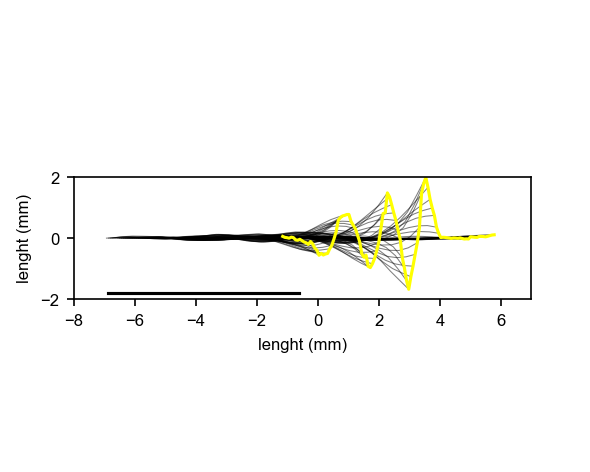

In [46]:
dx = 0.07
red_x = []
red_y = []

default()
widget()
arial()

fig = plt.figure(figsize=(10 / 2.54, 8 / 2.54),dpi=150)

for i, frame in enumerate(range(100)):
    x_shifted = tail_points_interp_o[frame, :, 0] - i * dx #+ i * dx
    y = tail_points_interp_o[frame, :, 1]

    plt.plot(x_shifted, y, 'k-', alpha=0.5, linewidth=0.5)

    # Tail tip (last point)
    tail_tip_x = x_shifted[-1]
    tail_tip_y = y[-1]
    red_x.append(tail_tip_x)
    red_y.append(tail_tip_y)

# Connect red dots with a line
plt.plot(red_x, red_y, '-', color=color_o, linewidth=1.5)

# --- Add scale bar ---
ax = plt.gca()
ax.set_aspect('equal')

# Choose position for scalebar
x0 = ax.get_xlim()[0] + 0.05 * (ax.get_xlim()[1] - ax.get_xlim()[0])  # 5% from left
y0 = ax.get_ylim()[0] - 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0])  # slightly below

y0 = -1.8
ax.plot([x0, x0 + L], [y0, y0], 'k-', linewidth=1.5)

ax.set_ylim(-2,2)

ax.set_xlabel("lenght (mm)")
ax.set_ylabel("lenght (mm)")

ax.set_xlim(-8,7)

fig.savefig(os.path.join(path_figures, "Fig_1e_midline_old.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_1e_midline_old.pdf"), format="pdf", bbox_inches='tight', dpi=200)

plt.show()

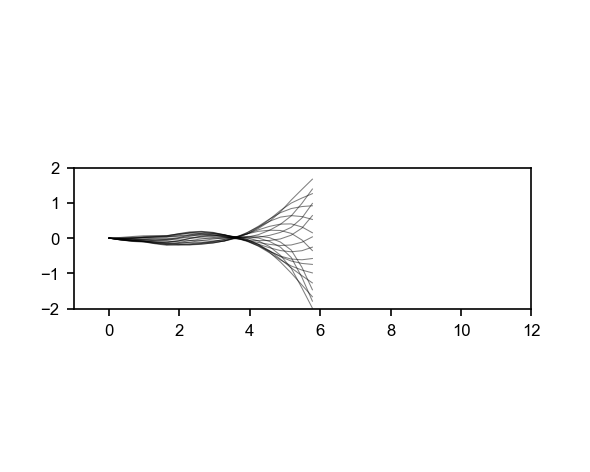

In [47]:
dx = 0.07
red_x = []
red_y = []

default()
widget()
arial()

fig = plt.figure(figsize=(10 / 2.54, 8 / 2.54),dpi=150)

for i, frame in enumerate(range(19)):
    frame0 = 28 + frame
    x_shifted = tail_points_interp_o[frame0, :, 0] 
    y = -tail_points_interp_o[frame0, :, 1]

    plt.plot(x_shifted, y, 'k-', alpha=0.5, linewidth=0.5)

    # Tail tip (last point)
    tail_tip_x = x_shifted[-1]
    tail_tip_y = y[-1]
    red_x.append(tail_tip_x)
    red_y.append(tail_tip_y)

# Connect red dots with a line
#plt.plot(red_x, red_y, '-', color=color_y, linewidth=1)

# --- Add scale bar ---
ax = plt.gca()
ax.set_aspect('equal')

# Choose position for scalebar
x0 = ax.get_xlim()[0] + 0.05 * (ax.get_xlim()[1] - ax.get_xlim()[0])  # 5% from left
y0 = ax.get_ylim()[0] - 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0])  # slightly below


ax.set_ylim(-2,2)
ax.set_xlim(-1,12)
#fig.savefig(os.path.join(path_figures, "midline_old_overimposed.pdf"), format="pdf")

plt.show()

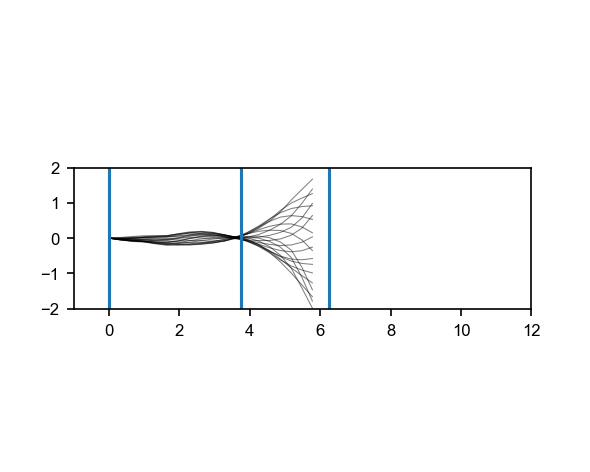

In [48]:
dx = 0.07
red_x = []
red_y = []

default()
widget()
arial()

fig = plt.figure(figsize=(10 / 2.54, 8 / 2.54),dpi=150)

for i, frame in enumerate(range(19)):
    frame0 = 28 + frame
    x_shifted = tail_points_interp_o[frame0, :, 0] 
    y = -tail_points_interp_o[frame0, :, 1]

    plt.plot(x_shifted, y, 'k-', alpha=0.5, linewidth=0.5)

    # Tail tip (last point)
    tail_tip_x = x_shifted[-1]
    tail_tip_y = y[-1]
    red_x.append(tail_tip_x)
    red_y.append(tail_tip_y)

# Connect red dots with a line
#plt.plot(red_x, red_y, '-', color=color_y, linewidth=1)

# --- Add scale bar ---
ax = plt.gca()
ax.set_aspect('equal')

# Choose position for scalebar
x0 = ax.get_xlim()[0] + 0.05 * (ax.get_xlim()[1] - ax.get_xlim()[0])  # 5% from left
y0 = ax.get_ylim()[0] - 0.05 * (ax.get_ylim()[1] - ax.get_ylim()[0])  # slightly below


ax.set_ylim(-2,2)
ax.set_xlim(-1,12)
#fig.savefig(os.path.join(path_figures, "midline_old_overimposed.pdf"), format="pdf")

ax.axvline(x = 0)
ax.axvline(x = L)
ax.axvline(x = L*3/5)


plt.show()